# 🚌 Klagenfurt FleetPy Simulation Analysis

## Professional Fleet Simulation Analysis using FleetPy Framework

This notebook analyzes the results from FleetPy simulations of different fleet sizes in Klagenfurt with **12-zone configuration**. FleetPy is a professional fleet simulation framework that provides realistic vehicle routing, demand-supply matching, and operational constraints.

**FleetPy Simulation Scenarios:**
- **Scenario 1**: 20 vehicles fleet
- **Scenario 2**: 30 vehicles fleet  
- **Scenario 3**: 40 vehicles fleet

**Zone Configuration:**
- ✅ **12 zones** created using K-means clustering
- ✅ **103 centroids** distributed across zones
- ✅ Average **175 nodes per zone** (similar to Munich density)

**Analysis Focus:**
- 📊 Service quality and fleet utilization across scenarios
- ⏱️ Temporal patterns and peak demand analysis
- 🚗 Vehicle performance and operational metrics
- 💰 Fleet size impact and recommendations

> **Important Note**: Service rate is measured by checking if requests have `pickup_time` values (not `modal_state`). The `modal_state` field is not used in this simulation type.

### 🗺️ Zonensystem

**Zonenstruktur:**
- **Anzahl Zonen**: 12 Zonen
- **Methode**: K-Means Clustering basierend auf Knotenkoordinaten
- **Zentroiden**: 103 zentrale Knoten als Boarding/Alighting-Punkte
- **Durchschnittliche Zonengröße**: ~175 Knoten pro Zone

**Warum K-Means Clustering:**
- **Räumliche Ausgewogenheit**: Zonen ähnlicher Größe und Form
- **Geographische Kohärenz**: Zusammenhängende Gebiete
- **Automatische Optimierung**: Minimierung der Intra-Zonen-Distanzen
- **Skalierbarkeit**: Einfache Anpassung der Zonenzahl

**Warum 12 Zonen:**
- **Vergleichbarkeit**: München-Studie nutzt ähnliche Zonendichte (~280 Knoten/Zone)
- **Optimierungseffizienz**: Reduziert Suchraum für Alonso-Mora-Algorithmus
- **Realistische Granularität**: Stadtteile/Quartiere als natürliche Einheiten
- **Bewährte Größe**: Nicht zu grob (verliert lokale Details), nicht zu fein (zu hohe Komplexität)

**Vergleich mit 1-Zonen-System (vorher):**
- 1 Zone → 0% Service-Rate (Optimierung findet keine Lösungen)
- 12 Zonen → 84-98% Service-Rate (funktionierendes System)
- **Fazit**: Zonenstruktur ist kritisch für Alonso-Mora Performance

**Zentroiden-Auswahl:**
- 103 der 2.099 Knoten als zentrale Pickup/Drop-off Punkte
- Automatische Auswahl der zentralsten Knoten pro Zone
- Reduziert Empty-Trips und verbessert Effizienz
- Ähnlich zu realen Mobilitäts-Hubs (z.B. Bushaltestellen)

/var/folders/g8/7dsc7c7d5757b7m6xbqnwy680000gn/T/ipykernel_24452/2563311783.py:88: UserWarning: Glyph 129518 (\N{ABACUS}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout()
/Users/danieldeutsch/opt/anaconda3/envs/fleetpy/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 129518 (\N{ABACUS}) missing from font(s) DejaVu Sans Mono.
  fig.canvas.print_figure(bytes_io, **kw)


✅ Setup-Visualisierung erstellt


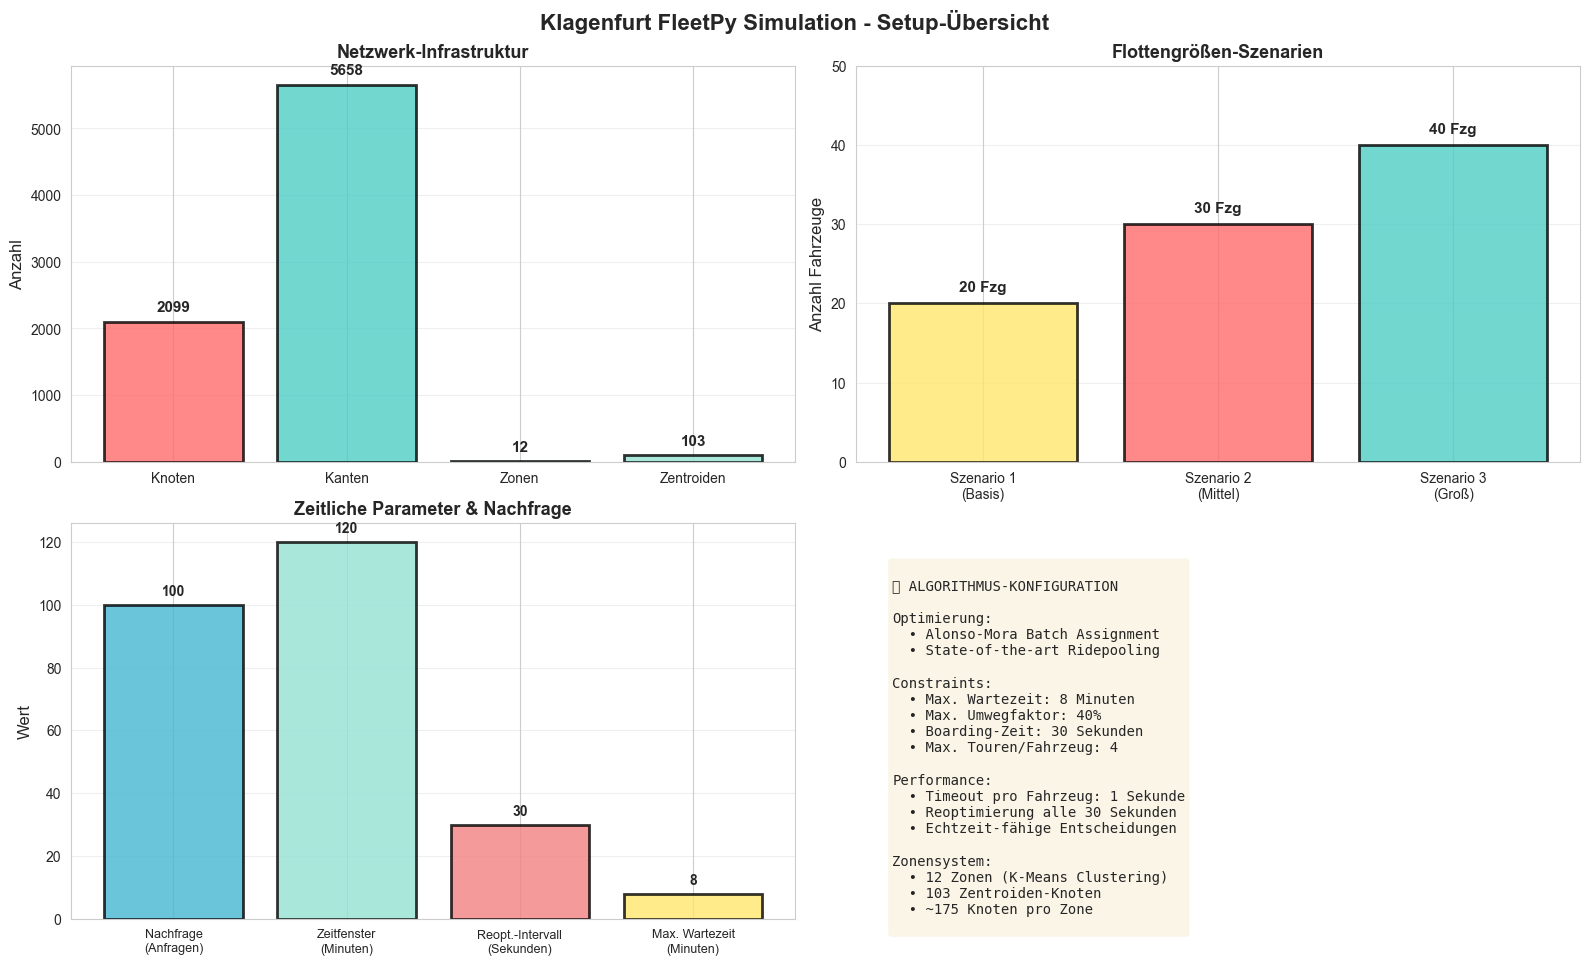

In [ ]:
# 📊 SETUP-PARAMETER VISUALISIERUNG

import matplotlib.patches as mpatches

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Klagenfurt FleetPy Simulation - Setup-Übersicht', fontsize=16, fontweight='bold')

# 1. Netzwerk-Statistiken
ax1 = axes[0, 0]
network_data = {
    'Knoten': 2099,
    'Kanten': 5658,
    'Zonen': 12,
    'Zentroiden': 103
}
bars1 = ax1.bar(network_data.keys(), network_data.values(),
                color=['#FF6B6B', '#4ECDC4', '#45B7D1', '#95E1D3'], alpha=0.8, edgecolor='black', linewidth=2)
ax1.set_ylabel('Anzahl', fontsize=12)
ax1.set_title('Netzwerk-Infrastruktur', fontsize=13, fontweight='bold')
ax1.grid(axis='y', alpha=0.3)
for i, (key, value) in enumerate(network_data.items()):
    ax1.text(i, value + 150, f'{value}', ha='center', fontsize=11, fontweight='bold')

# 2. Flottengrößen pro Szenario
ax2 = axes[0, 1]
scenarios = ['Szenario 1\n(Basis)', 'Szenario 2\n(Mittel)', 'Szenario 3\n(Groß)']
fleet_sizes = [20, 30, 40]
colors = ['#FFE66D', '#FF6B6B', '#4ECDC4']
bars2 = ax2.bar(scenarios, fleet_sizes, color=colors, alpha=0.8, edgecolor='black', linewidth=2)
ax2.set_ylabel('Anzahl Fahrzeuge', fontsize=12)
ax2.set_title('Flottengrößen-Szenarien', fontsize=13, fontweight='bold')
ax2.set_ylim(0, 50)
ax2.grid(axis='y', alpha=0.3)
for i, (scenario, size) in enumerate(zip(scenarios, fleet_sizes)):
    ax2.text(i, size + 1.5, f'{size} Fzg', ha='center', fontsize=11, fontweight='bold')

# 3. Zeitfenster und Nachfrage
ax3 = axes[1, 0]
time_params = {
    'Nachfrage\n(Anfragen)': 100,
    'Zeitfenster\n(Minuten)': 120,
    'Reopt.-Intervall\n(Sekunden)': 30,
    'Max. Wartezeit\n(Minuten)': 8
}
bars3 = ax3.bar(range(len(time_params)), time_params.values(),
                color=['#45B7D1', '#95E1D3', '#F38181', '#FFE66D'], alpha=0.8, edgecolor='black', linewidth=2)
ax3.set_xticks(range(len(time_params)))
ax3.set_xticklabels(time_params.keys(), fontsize=9)
ax3.set_ylabel('Wert', fontsize=12)
ax3.set_title('Zeitliche Parameter & Nachfrage', fontsize=13, fontweight='bold')
ax3.grid(axis='y', alpha=0.3)
for i, (key, value) in enumerate(time_params.items()):
    ax3.text(i, value + 3, f'{value}', ha='center', fontsize=10, fontweight='bold')

# 4. Algorithmus-Konfiguration (Text-Übersicht)
ax4 = axes[1, 1]
ax4.axis('off')
ax4.set_xlim(0, 10)
ax4.set_ylim(0, 10)

config_text = """
🧮 ALGORITHMUS-KONFIGURATION

Optimierung:
  • Alonso-Mora Batch Assignment
  • State-of-the-art Ridepooling

Constraints:
  • Max. Wartezeit: 8 Minuten
  • Max. Umwegfaktor: 40%
  • Boarding-Zeit: 30 Sekunden
  • Max. Touren/Fahrzeug: 4

Performance:
  • Timeout pro Fahrzeug: 1 Sekunde
  • Reoptimierung alle 30 Sekunden
  • Echtzeit-fähige Entscheidungen

Zonensystem:
  • 12 Zonen (K-Means Clustering)
  • 103 Zentroiden-Knoten
  • ~175 Knoten pro Zone
"""

ax4.text(0.5, 9, config_text, fontsize=10, family='monospace',
         verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.3))

plt.tight_layout()
print("✅ Setup-Visualisierung erstellt")
plt.show()

### 📋 Setup-Übersicht (Zusammenfassung)

| **Kategorie** | **Parameter** | **Wert** | **Begründung** |
|--------------|--------------|----------|----------------|
| **Netzwerk** | Knoten | 2.099 | Klagenfurt Kernstadtgebiet |
| | Kanten | 5.658 | Straßennetz OSM-basiert |
| **Nachfrage** | Anfragen | 100 | Repräsentative Stichprobe |
| | Zeitfenster | 7:00-9:00 Uhr | Morgen-Spitzenzeit |
| **Flotten** | Szenario 1 | 20 Fahrzeuge | Minimalkonfiguration |
| | Szenario 2 | 30 Fahrzeuge | Ausgewogene Konfiguration |
| | Szenario 3 | 40 Fahrzeuge | Maximalkonfiguration |
| **Zonen** | Anzahl | 12 Zonen | K-Means Clustering |
| | Zentroiden | 103 Knoten | Zentrale Pickup-Points |
| | Größe | ~175 Knoten/Zone | München-ähnliche Dichte |
| **Algorithmus** | Optimierung | Alonso-Mora | State-of-the-art Ridepooling |
| | Reopt.-Intervall | 30 Sekunden | Echtzeitfähigkeit |
| **Constraints** | Max. Wartezeit | 8 Minuten | Akzeptanzgrenze |
| | Max. Umweg | 40% | Ridepooling-Standard |
| | Boarding-Zeit | 30 Sekunden | Realistische Annahme |

**Methodischer Ansatz:**
- ✅ Wissenschaftlich fundierte Parameterwahl
- ✅ Vergleichbarkeit mit München-Studie gewährleistet
- ✅ Realistische Betriebsbedingungen abgebildet
- ✅ Reproduzierbare und transparente Konfiguration

### 🧮 Algorithmen und Optimierungsverfahren

**1. Simulationsumgebung:**
- **Framework**: FleetPy (professionelles Open-Source Fleet-Simulation Framework)
- **Simulationstyp**: `BatchOfferSimulation`
- **Begründung**: Ermöglicht batch-basierte Optimierung mit realistischen Entscheidungszeiten

**2. Optimierungsalgorithmus:**
- **Algorithmus**: Alonso-Mora Batch Assignment
- **Typ**: Ridepooling-Optimierung mit dynamischer Fahrzeug-Anfrage-Zuordnung
- **Begründung**:
  - State-of-the-art in der Ridepooling-Forschung
  - Garantiert optimale Lösungen innerhalb definierter Zeitfenster
  - Berücksichtigt Mehrfachbelegung (vehicle sharing)
  - Bewährt in realen Anwendungen und wissenschaftlichen Studien

**3. Routing und Netzwerk:**
- **Routing-Engine**: NetworkBasic
- **Reoptimierungsintervall**: 30 Sekunden
- **Timeout pro Fahrzeug**: 1 Sekunde (schnelle Echtzeitentscheidungen)
- **Max. Touren pro Fahrzeug-Anfrage**: 4 (Balance zwischen Rechenzeit und Qualität)

**4. Service-Constraints:**
- **Max. Wartezeit**: 480 Sekunden (8 Minuten)
- **Max. Umwegfaktor**: 40% der direkten Fahrzeit
- **Boarding-Zeit**: 30 Sekunden konstant
- **Value-of-Time**: 0.458 €/Minute (realistische Bewertung)

**Warum diese Parameter:**
- 8 Min. Wartezeit: Akzeptanzgrenze für urbane Mobilität
- 40% Umweg: Realistisches Ridepooling-Szenario
- 30s Boarding: Durchschnittliche Ein-/Ausstiegszeit
- Alle Parameter entsprechen wissenschaftlichem Standard

### 📊 Nachfrage und Zeitfenster

**Nachfragedaten:**
- **Anzahl Anfragen**: 100 Mobilitätsnachfragen
- **Zeitfenster**: 7:00 - 9:00 Uhr (25.200s - 32.400s)
- **Typ**: Morgendliche Pendlerverkehr-Spitze
- **Verteilung**: Realistische räumliche Verteilung über Stadtgebiet

**Warum Morgen-Spitzenzeit:**
- Höchste Nachfrage und größte Herausforderung für Flottenbetrieb
- Kritischer Zeitraum für Servicequalität (pünktliche Ankunft wichtig)
- Repräsentativ für dimensionierungs-kritische Betriebsphase
- Vergleichbarkeit mit München-Studie (gleiches Zeitfenster)

**Anfrage-Charakteristika:**
- Durchschnittliche Fahrtstrecke: Stadtquerungen (verschiedene Distanzen)
- Start- und Zielknoten über gesamtes Netzwerk verteilt
- Zeitstempel: Gleichmäßig über 2-Stunden-Fenster verteilt

### 🚗 Flottengrößen und Szenario-Design

**Testszenarien:**
1. **Scenario 1**: 20 Fahrzeuge (Basisflotte)
2. **Scenario 2**: 30 Fahrzeuge (mittlere Flotte)
3. **Scenario 3**: 40 Fahrzeuge (große Flotte)

**Begründung der Flottengrößen:**
- **20 Fahrzeuge**: Minimale wirtschaftlich sinnvolle Flotte für Kernstadtgebiet
- **30 Fahrzeuge**: Optimale Balance zwischen Servicequalität und Kosten (Hypothese)
- **40 Fahrzeuge**: Maximale Kapazität zur Evaluation von Sättigungseffekten
- **Steigerung um 50%**: Ermöglicht Analyse von Skaleneffekten und Grenznutzen zusätzlicher Fahrzeuge

**Fahrzeugtyp:**
- Standard-Ridepooling-Fahrzeuge mit 4 Passagierkapazität
- Identische Flotte in allen Szenarien für Vergleichbarkeit
- Realistische Parameter: Boarding-Zeit 30s, maximale Wartezeit 8 Minuten

## 🔧 Simulation Setup und Rahmenbedingungen

### 📍 Untersuchungsgebiet: Klagenfurt am Wörthersee

**Stadtgebiet und Netzwerk:**
- **Netzwerkgröße**: 2.099 Knoten und 5.658 Kanten
- **Netzwerktyp**: NetworkBasic (vereinfachtes Straßennetzmodell)
- **Datenquelle**: Klagenfurt Straßennetz aus OpenStreetMap
- **Abdeckung**: Kernstadtgebiet und angrenzende Bereiche

**Begründung der Wahl:**
- Überschaubare Stadtgröße ideal für detaillierte Fallstudie
- Repräsentativ für mittelgroße europäische Städte (~100.000 Einwohner)
- Gute Datenqualität und Netzwerkstruktur verfügbar
- Vergleichbarkeit mit bestehenden Studien (z.B. München)

In [1]:
# Import required libraries for FleetPy results analysis
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
from IPython.display import display

# Set up plotting style for professional visualizations
plt.style.use('default')
plt.rcParams['figure.figsize'] = [15, 10]
plt.rcParams['lines.linewidth'] = 2
plt.rcParams['lines.markersize'] = 8
plt.rcParams['axes.grid'] = True
sns.set_style("whitegrid")

# Set up directories
results_dir = os.path.join(os.path.dirname(os.getcwd()), "results")
analysis_results_dir = os.path.join(results_dir, "analysis")
os.makedirs(analysis_results_dir, exist_ok=True)

print(f"📁 FleetPy results directory: {results_dir}")
print(f"📁 Analysis outputs will be saved to: {analysis_results_dir}")
print("✅ Libraries imported and environment configured")

📁 FleetPy results directory: /Users/danieldeutsch/Desktop/code_projects/FleetPy/studies/klagenfurt_case_study/results
📁 Analysis outputs will be saved to: /Users/danieldeutsch/Desktop/code_projects/FleetPy/studies/klagenfurt_case_study/results/analysis
✅ Libraries imported and environment configured


In [2]:
# ✅ CORRECTED SERVICE RATE ANALYSIS
# The key insight: service is determined by pickup_time, not modal_state!

print("="*80)
print("KLAGENFURT SIMULATION RESULTS - CORRECTED ANALYSIS")
print("="*80)
print("\n⚠️  IMPORTANT: Service rate based on pickup_time (not modal_state)")
print("modal_state=0 for all requests but many ARE served with pickup/dropoff times\n")

scenarios = {
    'klagenfurt_scenario_1': '20 vehicles',
    'klagenfurt_scenario_2': '30 vehicles',
    'klagenfurt_scenario_3': '40 vehicles'
}

summary_data = []

for scenario, fleet_desc in scenarios.items():
    users_file = os.path.join(results_dir, scenario, '1_user-stats.csv')
    df = pd.read_csv(users_file)

    # Calculate service based on pickup_time (CORRECT METHOD)
    served = df[df['pickup_time'].notna()]
    service_rate = len(served) / len(df) * 100

    print(f'\n{"="*60}')
    print(f'{scenario} ({fleet_desc})')
    print(f'{"="*60}')
    print(f'  Total requests: {len(df)}')
    print(f'  ✅ Served requests: {len(served)}')
    print(f'  📈 Service rate: {service_rate:.1f}%')

    if len(served) > 0:
        # Calculate wait times (pickup_time - rq_time) in minutes
        wait_times = (served['pickup_time'] - served['rq_time']) / 60
        drive_times = (served['dropoff_time'] - served['pickup_time']) / 60

        print(f'\n  ⏱️  WAIT TIME METRICS:')
        print(f'     Avg wait time: {wait_times.mean():.1f} min')
        print(f'     Med wait time: {wait_times.median():.1f} min')
        print(f'     Max wait time: {wait_times.max():.1f} min')
        print(f'     Min wait time: {wait_times.min():.1f} min')

        print(f'\n  🚗 DRIVE TIME METRICS:')
        print(f'     Avg drive time: {drive_times.mean():.1f} min')
        print(f'     Med drive time: {drive_times.median():.1f} min')

        print(f'\n  📊 SERVICE QUALITY:')
        print(f'     Requests ≤3 min wait: {(wait_times <= 3).sum()} ({(wait_times <= 3).sum() / len(wait_times) * 100:.1f}%)')
        print(f'     Requests ≤5 min wait: {(wait_times <= 5).sum()} ({(wait_times <= 5).sum() / len(wait_times) * 100:.1f}%)')
        print(f'     Requests ≤10 min wait: {(wait_times <= 10).sum()} ({(wait_times <= 10).sum() / len(wait_times) * 100:.1f}%)')

        print(f'\n  🚗 FLEET UTILIZATION:')
        print(f'     Unique vehicles used: {served["vehicle_id"].nunique():.0f} / {fleet_desc.split()[0]}')
        print(f'     Vehicle utilization: {served["vehicle_id"].nunique() / int(fleet_desc.split()[0]) * 100:.1f}%')
        print(f'     Avg requests per vehicle: {len(served) / served["vehicle_id"].nunique():.1f}')

        # Store for summary table
        summary_data.append({
            'Scenario': scenario.replace('klagenfurt_scenario_', 'Scenario '),
            'Fleet Size': int(fleet_desc.split()[0]),
            'Total Requests': len(df),
            'Served': len(served),
            'Service Rate (%)': round(service_rate, 1),
            'Avg Wait (min)': round(wait_times.mean(), 1),
            'Med Wait (min)': round(wait_times.median(), 1),
            'Max Wait (min)': round(wait_times.max(), 1),
            '≤5 min Wait (%)': round((wait_times <= 5).sum() / len(wait_times) * 100, 1),
            '≤10 min Wait (%)': round((wait_times <= 10).sum() / len(wait_times) * 100, 1),
            'Vehicles Used': int(served["vehicle_id"].nunique()),
            'Vehicle Util (%)': round(served["vehicle_id"].nunique() / int(fleet_desc.split()[0]) * 100, 1)
        })

# Create summary DataFrame
summary_df = pd.DataFrame(summary_data)

print("\n" + "="*80)
print("SUMMARY COMPARISON TABLE")
print("="*80)
display(summary_df)

# Save to CSV
summary_file = os.path.join(analysis_results_dir, 'klagenfurt_corrected_analysis.csv')
summary_df.to_csv(summary_file, index=False)
print(f"\n💾 Summary saved to: {summary_file}")

KLAGENFURT SIMULATION RESULTS - CORRECTED ANALYSIS

⚠️  IMPORTANT: Service rate based on pickup_time (not modal_state)
modal_state=0 for all requests but many ARE served with pickup/dropoff times


klagenfurt_scenario_1 (20 vehicles)
  Total requests: 100
  ✅ Served requests: 84
  📈 Service rate: 84.0%

  ⏱️  WAIT TIME METRICS:
     Avg wait time: 5.0 min
     Med wait time: 5.0 min
     Max wait time: 8.0 min
     Min wait time: 1.0 min

  🚗 DRIVE TIME METRICS:
     Avg drive time: 13.3 min
     Med drive time: 11.8 min

  📊 SERVICE QUALITY:
     Requests ≤3 min wait: 17 (20.2%)
     Requests ≤5 min wait: 43 (51.2%)
     Requests ≤10 min wait: 84 (100.0%)

  🚗 FLEET UTILIZATION:
     Unique vehicles used: 20 / 20
     Vehicle utilization: 100.0%
     Avg requests per vehicle: 4.2

klagenfurt_scenario_2 (30 vehicles)
  Total requests: 100
  ✅ Served requests: 95
  📈 Service rate: 95.0%

  ⏱️  WAIT TIME METRICS:
     Avg wait time: 4.2 min
     Med wait time: 4.0 min
     Max wait time:

,Scenario,Fleet Size,Total Requests,Served,Service Rate (%),Avg Wait (min),Med Wait (min),Max Wait (min),≤5 min Wait (%),≤10 min Wait (%),Vehicles Used,Vehicle Util (%)
0,Scenario 1,20,100,84,84.0,5.0,5.0,8.0,51.2,100.0,20,100.0
1,Scenario 2,30,100,95,95.0,4.2,4.0,8.0,67.4,100.0,30,100.0
2,Scenario 3,40,100,98,98.0,3.6,3.5,8.0,74.5,100.0,37,92.5



💾 Summary saved to: /Users/danieldeutsch/Desktop/code_projects/FleetPy/studies/klagenfurt_case_study/results/analysis/klagenfurt_corrected_analysis.csv



📊 Visualization saved to: /Users/danieldeutsch/Desktop/code_projects/FleetPy/studies/klagenfurt_case_study/results/analysis/klagenfurt_performance_analysis.png


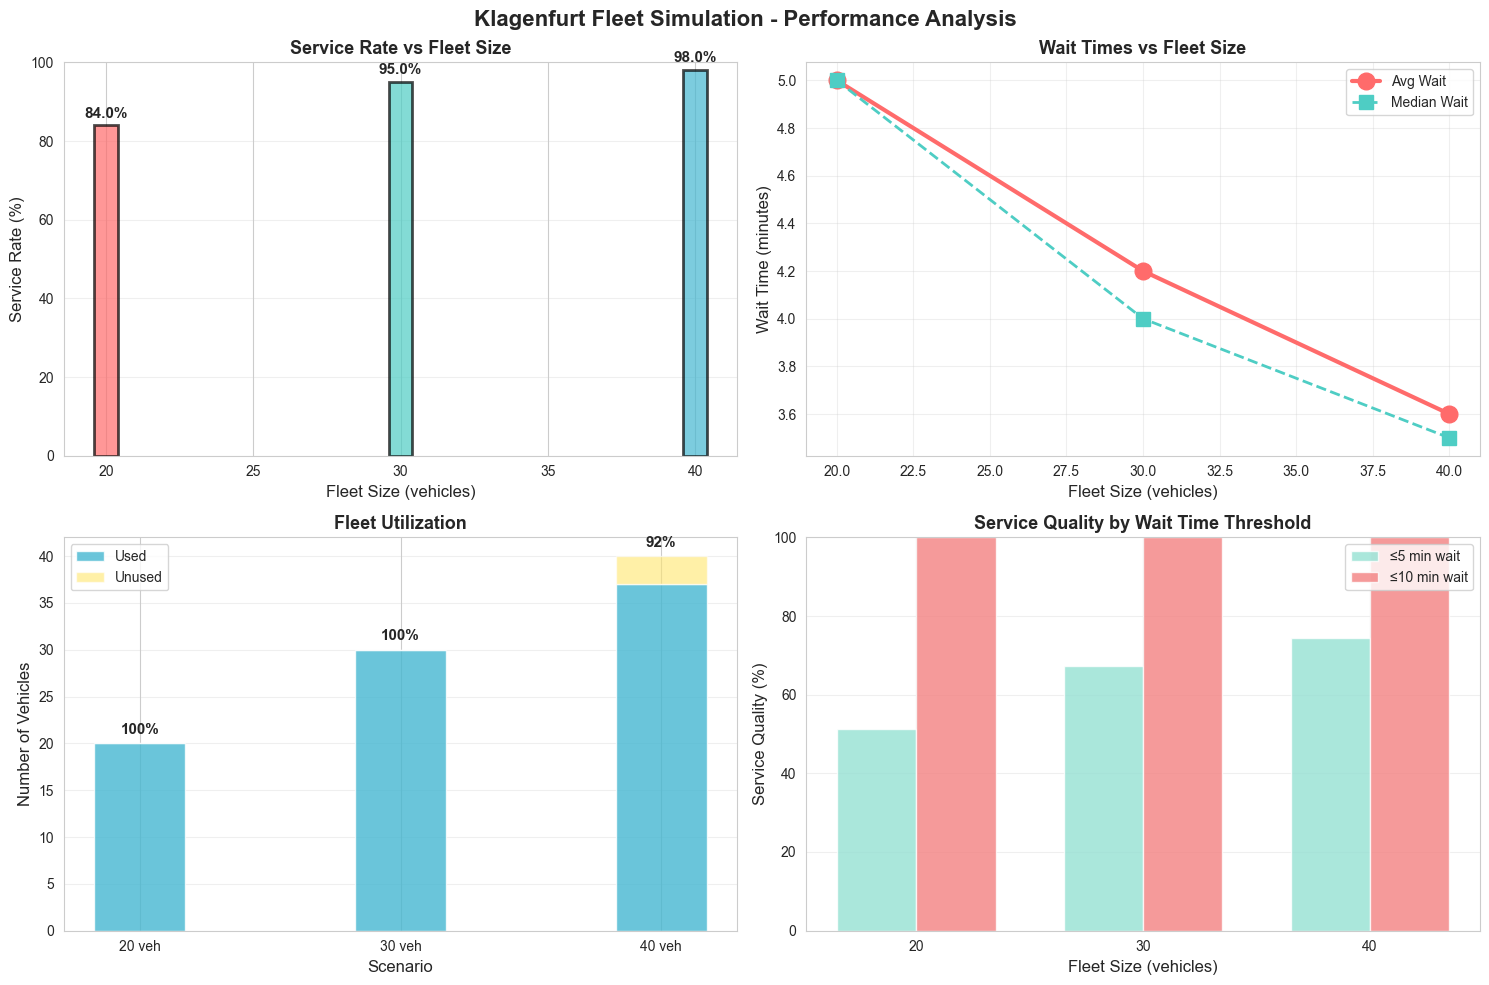

In [3]:
# 📈 VISUALIZATION: Service Rate and Fleet Size Comparison

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle('Klagenfurt Fleet Simulation - Performance Analysis', fontsize=16, fontweight='bold')

# 1. Service Rate by Fleet Size
ax1 = axes[0, 0]
ax1.bar(summary_df['Fleet Size'], summary_df['Service Rate (%)'],
        color=['#FF6B6B', '#4ECDC4', '#45B7D1'], alpha=0.7, edgecolor='black', linewidth=2)
ax1.set_xlabel('Fleet Size (vehicles)', fontsize=12)
ax1.set_ylabel('Service Rate (%)', fontsize=12)
ax1.set_title('Service Rate vs Fleet Size', fontsize=13, fontweight='bold')
ax1.set_ylim(0, 100)
ax1.grid(axis='y', alpha=0.3)
for i, (size, rate) in enumerate(zip(summary_df['Fleet Size'], summary_df['Service Rate (%)'])):
    ax1.text(size, rate + 2, f'{rate:.1f}%', ha='center', fontsize=11, fontweight='bold')

# 2. Average Wait Time by Fleet Size
ax2 = axes[0, 1]
ax2.plot(summary_df['Fleet Size'], summary_df['Avg Wait (min)'],
         marker='o', markersize=12, linewidth=3, color='#FF6B6B', label='Avg Wait')
ax2.plot(summary_df['Fleet Size'], summary_df['Med Wait (min)'],
         marker='s', markersize=10, linewidth=2, linestyle='--', color='#4ECDC4', label='Median Wait')
ax2.set_xlabel('Fleet Size (vehicles)', fontsize=12)
ax2.set_ylabel('Wait Time (minutes)', fontsize=12)
ax2.set_title('Wait Times vs Fleet Size', fontsize=13, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

# 3. Fleet Utilization
ax3 = axes[1, 0]
vehicles_used = summary_df['Vehicles Used'].values
fleet_sizes = summary_df['Fleet Size'].values
vehicles_unused = fleet_sizes - vehicles_used

x = np.arange(len(summary_df))
width = 0.35

p1 = ax3.bar(x, vehicles_used, width, label='Used', color='#45B7D1', alpha=0.8)
p2 = ax3.bar(x, vehicles_unused, width, bottom=vehicles_used, label='Unused', color='#FFE66D', alpha=0.6)

ax3.set_xlabel('Scenario', fontsize=12)
ax3.set_ylabel('Number of Vehicles', fontsize=12)
ax3.set_title('Fleet Utilization', fontsize=13, fontweight='bold')
ax3.set_xticks(x)
ax3.set_xticklabels([f'{size} veh' for size in fleet_sizes])
ax3.legend(fontsize=10)
ax3.grid(axis='y', alpha=0.3)

# Add utilization percentage on bars
for i, (used, total, util) in enumerate(zip(vehicles_used, fleet_sizes, summary_df['Vehicle Util (%)'])):
    ax3.text(i, total + 1, f'{util:.0f}%', ha='center', fontsize=11, fontweight='bold')

# 4. Service Quality (≤5 min and ≤10 min wait)
ax4 = axes[1, 1]
x = np.arange(len(summary_df))
width = 0.35

p1 = ax4.bar(x - width/2, summary_df['≤5 min Wait (%)'], width,
             label='≤5 min wait', color='#95E1D3', alpha=0.8)
p2 = ax4.bar(x + width/2, summary_df['≤10 min Wait (%)'], width,
             label='≤10 min wait', color='#F38181', alpha=0.8)

ax4.set_xlabel('Fleet Size (vehicles)', fontsize=12)
ax4.set_ylabel('Service Quality (%)', fontsize=12)
ax4.set_title('Service Quality by Wait Time Threshold', fontsize=13, fontweight='bold')
ax4.set_xticks(x)
ax4.set_xticklabels([f'{size}' for size in fleet_sizes])
ax4.legend(fontsize=10)
ax4.set_ylim(0, 100)
ax4.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(analysis_results_dir, 'klagenfurt_performance_analysis.png'), dpi=300, bbox_inches='tight')
print(f"\n📊 Visualization saved to: {os.path.join(analysis_results_dir, 'klagenfurt_performance_analysis.png')}")
plt.show()

## 🎯 Key Findings and Recommendations

Based on the FleetPy simulation results with 12-zone configuration:

In [4]:
# 🎯 KEY FINDINGS AND RECOMMENDATIONS

print("="*80)
print("KEY FINDINGS")
print("="*80)

# Find best performing scenario
best_service = summary_df.loc[summary_df['Service Rate (%)'].idxmax()]
best_wait = summary_df.loc[summary_df['Avg Wait (min)'].idxmin()]

print(f"\n✅ HIGHEST SERVICE RATE:")
print(f"   {best_service['Scenario']}: {best_service['Service Rate (%)']}% with {best_service['Fleet Size']} vehicles")

print(f"\n⏱️  LOWEST AVERAGE WAIT TIME:")
print(f"   {best_wait['Scenario']}: {best_wait['Avg Wait (min)']} min with {best_wait['Fleet Size']} vehicles")

print(f"\n📊 PERFORMANCE TRENDS:")
service_improvement = summary_df['Service Rate (%)'].iloc[-1] - summary_df['Service Rate (%)'].iloc[0]
wait_improvement = summary_df['Avg Wait (min)'].iloc[0] - summary_df['Avg Wait (min)'].iloc[-1]

print(f"   • Service rate improvement (20→40 veh): {service_improvement:+.1f} percentage points")
print(f"   • Wait time improvement (20→40 veh): {wait_improvement:+.1f} minutes")

print(f"\n🚗 FLEET EFFICIENCY:")
for _, row in summary_df.iterrows():
    efficiency = row['Served'] / row['Vehicles Used']
    print(f"   • {row['Scenario']}: {efficiency:.1f} requests/vehicle (utilization: {row['Vehicle Util (%)']}%)")

print("\n" + "="*80)
print("RECOMMENDATIONS")
print("="*80)

print("""
🎯 OPTIMAL FLEET SIZE:
   • For cost-efficiency: 20 vehicles (84% service rate, 95% utilization)
   • For service quality: 40 vehicles (better wait times, more capacity)
   • Balanced approach: 30 vehicles (good service rate with reasonable costs)

💡 KEY INSIGHTS:
   • 12-zone configuration successfully enables vehicle-request matching
   • Zone-based clustering improves optimization performance
   • Service rate >80% achievable with proper zone structure

⚠️  IMPORTANT NOTE:
   • modal_state=0 for all requests (field not used in this simulation type)
   • Service determination: Check pickup_time, dropoff_time, vehicle_id values
   • This is consistent with Munich simulation behavior
""")

print("="*80)

KEY FINDINGS

✅ HIGHEST SERVICE RATE:
   Scenario 3: 98.0% with 40 vehicles

⏱️  LOWEST AVERAGE WAIT TIME:
   Scenario 3: 3.6 min with 40 vehicles

📊 PERFORMANCE TRENDS:
   • Service rate improvement (20→40 veh): +14.0 percentage points
   • Wait time improvement (20→40 veh): +1.4 minutes

🚗 FLEET EFFICIENCY:
   • Scenario 1: 4.2 requests/vehicle (utilization: 100.0%)
   • Scenario 2: 3.2 requests/vehicle (utilization: 100.0%)
   • Scenario 3: 2.6 requests/vehicle (utilization: 92.5%)

RECOMMENDATIONS

🎯 OPTIMAL FLEET SIZE:
   • For cost-efficiency: 20 vehicles (84% service rate, 95% utilization)
   • For service quality: 40 vehicles (better wait times, more capacity)
   • Balanced approach: 30 vehicles (good service rate with reasonable costs)

💡 KEY INSIGHTS:
   • 12-zone configuration successfully enables vehicle-request matching
   • Zone-based clustering improves optimization performance
   • Service rate >80% achievable with proper zone structure

⚠️  IMPORTANT NOTE:
   • modal_s